# Milestone 3 — Deep learning models (Session 7)

**Course:** Computer Vision and Speech Recognition — EADA · **Student:** Kristof Papp

**Code (GitHub):** https://github.com/kristofpapp330/milk10k-cv-course/blob/main/notebooks/m3_deep_models.ipynb

| what | file |
|---|---|
| this notebook (run on Google Colab, T4 GPU) | `notebooks/m3_deep_models.ipynb` |
| models, training loop, preprocessing, checkpoints | `milk10k_pipeline/deep.py` |
| linear head on frozen features (Session 6 code) | `milk10k_pipeline/mlp.py` |
| results (predictions, histories, registry) | `outputs/deep/` |

**Target (Path A of the brief):** the 3 classes of `diagnosis_1` (Benign / Malignant / Indeterminate),
the target of every earlier scoreboard. Metric: **macro-F1**, same Milestone 1 lesion-level split.

**Models of this milestone**
1. **CNN from scratch**: 4 conv blocks + global average pooling, all weights learned on MILK10k.
2. **ResNet-18 frozen + linear head** (Session 7 strategy 1): ImageNet backbone as a feature extractor.
3. **ResNet-18 fine-tune layer4 + fc** (strategy 2, "the usual best default").
4. **ResNet-18 fine-tune layer3 + layer4 + fc** (the Session 7 mini challenge).

Same for all: 224×224 input, ImageNet normalisation, class-weighted cross-entropy, Adam
(1e-3 for the new head, 1e-4 for pretrained layers), batch 64, early stopping on validation macro-F1,
training augmentation = the Milestone 1 table (flips, ±20° rotation, mild brightness/hue).

## 0. Setup (Google Colab)
**Before running:** *Runtime → Change runtime type → T4 GPU*. Then *Runtime → Run all*.
Google asks once for permission to use your Drive: everything that must survive the session
(image cache, predictions, checkpoints) is saved in `MyDrive/milk10k_project/`.

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
QUICK = os.environ.get("MILK10K_QUICK") == "1"        # offline test mode only (tiny subset, 1 epoch)
REPO_URL = "https://github.com/kristofpapp330/milk10k-cv-course.git"
DATA_URL = "https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip"

def run(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/milk10k_project")
    repo = Path("/content/milk10k-cv-course")
    if repo.exists():
        run(f"git -C {repo} pull --ff-only")
    else:
        run(f"git clone --depth 1 {REPO_URL} {repo}")
    os.chdir(repo)
    data_root = Path("/content/milk10k")
    if not list(data_root.rglob("metadata.csv")):
        zip_path = WORK / "milk10k.zip"                   # option 1: you uploaded the zip to Drive
        if not zip_path.exists():                         # option 2: download it (about 1-2 minutes)
            zip_path = Path("/content/milk10k.zip")
            run(f"wget -q -O {zip_path} {DATA_URL}")
        print("unzipping ...")
        zipfile.ZipFile(zip_path).extractall(data_root)
    os.environ["MILK10K_DIR"] = str(next(data_root.rglob("metadata.csv")).parent)
else:                                                     # local run (testing)
    repo = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(repo)
    WORK = Path(os.environ.get("MILK10K_WORK", repo / "outputs" / "deep_work"))

sys.path.insert(0, str(Path.cwd()))
WORK.mkdir(parents=True, exist_ok=True)
DEEP = WORK / "outputs_deep"                              # small results -> later copied to outputs/deep in the repo
PRED = DEEP / "predictions"
CKPT = WORK / "checkpoints"                               # model weights
FIG = DEEP / "figures"
for d in (DEEP, PRED, CKPT, FIG):
    d.mkdir(parents=True, exist_ok=True)

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from milk10k_pipeline import config, deep, evaluation as ev, mlp
from milk10k_pipeline.data_io import find_images

device = deep.get_device()
NUM_WORKERS = 2 if IN_COLAB else 0
print("device:", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "none")
print("data:", config.DATA_DIR, "| results:", WORK)
if IN_COLAB and device.type != "cuda":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then run again.")

Mounted at /content/drive
$ git clone --depth 1 https://github.com/kristofpapp330/milk10k-cv-course.git /content/milk10k-cv-course
$ wget -q -O /content/milk10k.zip https://isic-archive.s3.amazonaws.com/dois/10.34970-648456/milk10k.zip
unzipping ...
device: cuda | GPU: Tesla T4
data: /content/milk10k | results: /content/drive/MyDrive/milk10k_project


### The data: Milestone 1 split (by lesion), one dermoscopic image per lesion

In [2]:
splits = {}
for name in ["train", "val", "test"]:
    df = pd.read_csv(config.SPLITS_DIR / f"{name}.csv")
    df = df[df["view"].isin(config.VIEWS)].reset_index(drop=True)
    df["y3"] = df["diagnosis_1"].map({c: i for i, c in enumerate(deep.CLASSES3)})
    df["y11"] = df["dx"].map({c: i for i, c in enumerate(deep.CLASSES11)})
    if QUICK:
        df = pd.concat([g.head(40) for _, g in df.groupby("y3")]).reset_index(drop=True)
    splits[name] = df
train, val, test = splits["train"], splits["val"], splits["test"]
assert not (set(train.lesion_id) & set(val.lesion_id)) and not (set(train.lesion_id) & set(test.lesion_id)) \
    and not (set(val.lesion_id) & set(test.lesion_id)), "lesion leakage between splits!"
print({k: len(v) for k, v in splits.items()}, "lesions")

image_paths = find_images()
all_ids = pd.concat([train, val, test])["isic_id"].tolist()
cache = deep.build_cache(all_ids, image_paths, cache_path=WORK / ("cache224_quick.npz" if QUICK else "cache224.npz"))
n_tr, n_va = len(train), len(val)
IMG = {"train": cache[:n_tr], "val": cache[n_tr:n_tr + n_va], "test": cache[n_tr + n_va:]}
Y3 = {s: splits[s]["y3"].to_numpy() for s in splits}
Y11 = {s: splits[s]["y11"].to_numpy() for s in splits}
EPOCHS = 1 if QUICK else None

{'train': 3143, 'val': 1048, 'test': 1049} lesions
  500/5240 images prepared (1s)
  1000/5240 images prepared (2s)
  1500/5240 images prepared (3s)
  2000/5240 images prepared (4s)
  2500/5240 images prepared (5s)
  3000/5240 images prepared (6s)
  3500/5240 images prepared (8s)
  4000/5240 images prepared (9s)
  4500/5240 images prepared (11s)
  5000/5240 images prepared (12s)
  5240/5240 images prepared (12s)


---
## Common helpers (identical in the M3 and M4 notebooks)
Every deep model is scored like every earlier model: **3-class macro-F1 on the same validation lesions**.
Test predictions are saved now, but they are only looked at in the Milestone 4 scoreboard, after the
best model has been chosen on validation.

In [3]:
REGISTRY = DEEP / "models.json"      # every deep model: its file names and validation numbers

def file_key(name):
    return name.replace("/", "-").replace(" ", "_").replace("+", "and")

def save_predictions(name, proba_val, proba_test, info, Y=None):
    Y = Y3 if Y is None else Y
    key = file_key(name)
    np.savez(PRED / f"{key}.npz", val=proba_val, test=proba_test)
    f1 = ev.macro_f1(Y["val"], proba_val.argmax(1), proba_val.shape[1])
    registry = json.loads(REGISTRY.read_text()) if REGISTRY.exists() else {}
    registry[name] = {"predictions": f"{key}.npz", "val_macro_f1": round(f1, 4), **info}
    REGISTRY.write_text(json.dumps(registry, indent=2))
    print(f"{name}: validation macro-F1 = {f1:.3f}")

def plot_history(hist, title, name):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(hist.epoch, hist.train_loss, "--", label="train"); ax[0].plot(hist.epoch, hist.val_loss, label="validation")
    ax[0].set_title("class-weighted cross-entropy"); ax[0].legend()
    ax[1].plot(hist.epoch, hist.val_macro_f1, color="#eb6834"); ax[1].set_title("validation macro-F1")
    ax[1].axvline(hist.val_macro_f1.idxmax() + 1, ls=":", color="gray")
    for a in ax: a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=120); plt.show()

def finetune(name, Y=None, classes=None, tag=""):
    """Train one recipe of deep.RECIPES end to end and save its predictions + checkpoint.
    Y / classes: the labels (default: the 3 diagnosis_1 classes); tag is added to the saved name."""
    Y, classes = (Y3, deep.CLASSES3) if Y is None else (Y, classes)
    k = len(classes)
    r = deep.RECIPES[name]
    out_name = name + tag
    model = deep.build_model(r["arch"], n_classes=k, pretrained=r["pretrained"])
    deep.freeze(model, r["trainable"])
    print(f"{name}: {deep.n_trainable(model):,} trainable of {deep.n_total(model):,} parameters")
    tl = deep.make_loader(IMG["train"], Y["train"], train=True, num_workers=NUM_WORKERS)
    vl = deep.make_loader(IMG["val"], Y["val"], train=False, num_workers=NUM_WORKERS)
    te = deep.make_loader(IMG["test"], Y["test"], train=False, num_workers=NUM_WORKERS)
    start = time.time()
    model, hist, best_epoch = deep.train_model(model, r, tl, vl, Y["train"], Y["val"], k, device, epochs=EPOCHS)
    minutes = (time.time() - start) / 60
    hist.to_csv(DEEP / f"history_{file_key(out_name)}.csv", index=False)
    plot_history(hist, f"{out_name} ({minutes:.1f} min)", file_key(out_name))
    ckpt = deep.save_checkpoint(model, CKPT / f"{file_key(out_name)}.pt", r["arch"],
                                classes, r["trainable"], r["pretrained"])
    save_predictions(out_name, deep.predict_proba(model, vl, device), deep.predict_proba(model, te, device),
                     {"kind": "finetune", "arch": r["arch"], "trainable params": deep.n_trainable(model),
                      "best epoch": best_epoch, "minutes": round(minutes, 1),
                      "sec per epoch": round(hist.seconds.mean(), 1), "checkpoint": ckpt.name}, Y=Y)
    return model, hist

def frozen_head(name, arch, seeds=(0, 1, 2), Y=None, classes=None, tag=""):
    """Session 7 strategy 1 / Session 9 fair comparison: frozen backbone -> embeddings once -> linear head
    trained with the Session 6 code (class weights, Adam 1e-3, batch 64, early stopping), 3 seeds."""
    emb_file = WORK / f"embeddings_{arch}{'_quick' if QUICK else ''}.npz"
    if emb_file.exists():
        E = dict(np.load(emb_file))
    else:
        start = time.time()
        E = {s: deep.backbone_embeddings(arch, IMG[s], device, num_workers=NUM_WORKERS) for s in IMG}
        np.savez(emb_file, **E)
        print(f"embeddings computed in {time.time() - start:.0f}s: {E['train'].shape[1]} numbers per lesion")
    Y, classes = (Y3, deep.CLASSES3) if Y is None else (Y, classes)
    k, out_name = len(classes), name + tag
    runs = []
    for seed in seeds:
        head, hist, best_epoch = mlp.train_mlp(E["train"].astype(np.float32), Y["train"], E["val"].astype(np.float32),
                                               Y["val"], k, hidden=(), seed=seed, epochs=EPOCHS or 50)
        runs.append((hist["val_macro_f1"].max(), seed, head, hist))
    vals = [r[0] for r in runs]
    best_f1, best_seed, head, hist = max(runs, key=lambda r: r[0])
    full = deep.model_from_frozen_head(arch, head[0], k)
    head_prefix = ["fc"] if arch == "resnet18" else ["heads"]
    ckpt = deep.save_checkpoint(full, CKPT / f"{file_key(out_name)}.pt", arch, classes, head_prefix)
    p_val = mlp.predict_proba(head, E["val"].astype(np.float32))
    p_test = mlp.predict_proba(head, E["test"].astype(np.float32))
    save_predictions(out_name, p_val, p_test, {"kind": "frozen", "arch": arch, "trainable params": mlp.n_parameters(head),
                                           "seed val macro-F1 (3 seeds)": [round(v, 3) for v in vals],
                                           "chosen seed": best_seed, "best epoch": int(hist["val_macro_f1"].idxmax()) + 1,
                                           "checkpoint": ckpt.name}, Y=Y)
    plot_history(hist, f"{out_name} (linear head on frozen embeddings, seed {best_seed})", file_key(out_name))
    return hist

---
## 1. What the networks see
The cache holds every dermoscopic image after `prepare_image()` (PIL resize to 224×224): exactly what
validation, test, `predict()` and the leaderboard submission use. Bottom row: training augmentation.

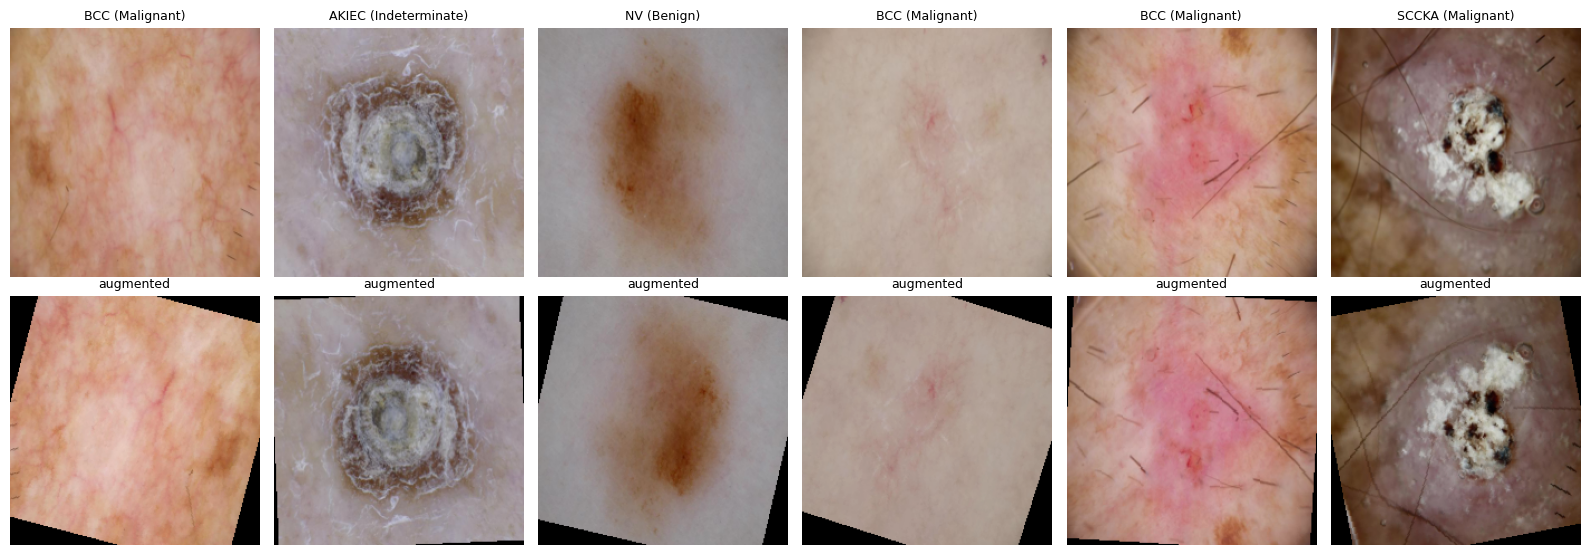

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
idx = np.random.default_rng(config.SEED).choice(n_tr, 6, replace=False)
for j, i in enumerate(idx):
    axes[0, j].imshow(IMG["train"][i]); axes[0, j].set_title(f"{train.dx[i]} ({train.diagnosis_1[i]})", fontsize=9)
    aug = deep.TRAIN_TRANSFORM(deep.Image.fromarray(IMG["train"][i])).permute(1, 2, 0).numpy()
    aug = aug * np.array(deep.IMAGENET_STD) + np.array(deep.IMAGENET_MEAN)
    axes[1, j].imshow(np.clip(aug, 0, 1)); axes[1, j].set_title("augmented", fontsize=9)
for a in axes.flat: a.axis("off")
plt.tight_layout(); plt.savefig(FIG / "m3_inputs.png", dpi=110); plt.show()

## 2. CNN from scratch
Every weight starts random and is learned on 3,143 training lesions only.

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(

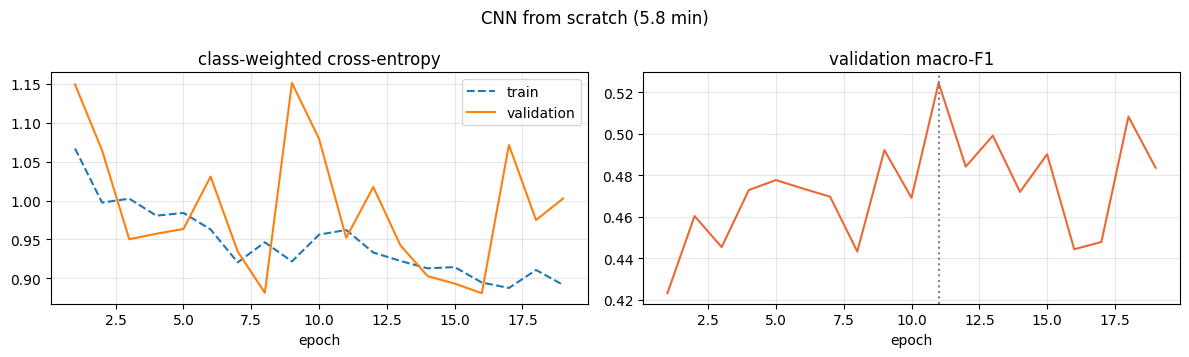

CNN from scratch: validation macro-F1 = 0.525


In [5]:
from milk10k_pipeline.deep import SmallCNN
print(SmallCNN(3))
cnn, cnn_hist = finetune("CNN from scratch")

## 3. ResNet-18, frozen backbone + linear head (strategy 1)
The ImageNet backbone turns each lesion into 512 numbers once; a single linear layer 512 → 3
(1,539 weights) is trained on them with the Session 6 code, 3 seeds.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s]


embeddings computed in 9s: 512 numbers per lesion
ResNet-18 frozen + head: validation macro-F1 = 0.603


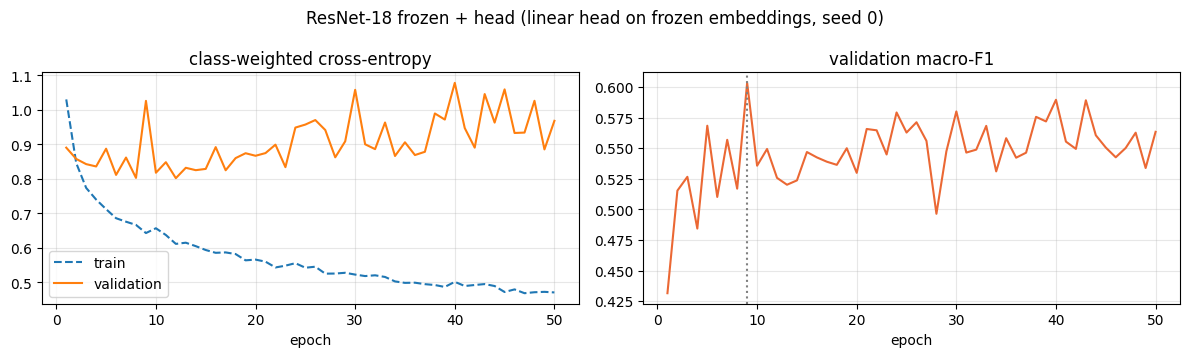

,epoch,train_loss,val_loss,val_macro_f1
0,1,1.030080,0.890258,0.431443
1,2,0.845649,0.857587,0.515311
2,3,0.773515,0.842514,0.526590
3,4,0.739803,0.835748,0.484291
4,5,0.711953,0.887240,0.568355
5,6,0.685754,0.811271,0.510146
6,7,0.675597,0.861609,0.556854
7,8,0.666342,0.802606,0.516920
8,9,0.642774,1.025876,0.603407
9,10,0.656616,0.817549,0.535687


In [6]:
frozen_head("ResNet-18 frozen + head", "resnet18")

## 4. ResNet-18, fine-tune layer4 + fc (strategy 2)

ResNet-18 fine-tune layer4: 8,395,267 trainable of 11,178,051 parameters
  epoch  1: train loss 0.957 | val loss 0.872 | val macro-F1 0.473 | 17s
  epoch  2: train loss 0.682 | val loss 0.828 | val macro-F1 0.486 | 17s
  epoch  3: train loss 0.593 | val loss 1.000 | val macro-F1 0.424 | 16s
  epoch  4: train loss 0.585 | val loss 0.864 | val macro-F1 0.500 | 17s
  epoch  5: train loss 0.526 | val loss 1.268 | val macro-F1 0.584 | 17s
  epoch  6: train loss 0.479 | val loss 1.150 | val macro-F1 0.588 | 16s
  epoch  7: train loss 0.413 | val loss 1.181 | val macro-F1 0.602 | 17s
  epoch  8: train loss 0.422 | val loss 1.818 | val macro-F1 0.579 | 17s
  epoch  9: train loss 0.382 | val loss 1.633 | val macro-F1 0.569 | 17s
  epoch 10: train loss 0.353 | val loss 1.862 | val macro-F1 0.610 | 17s
  epoch 11: train loss 0.365 | val loss 1.755 | val macro-F1 0.530 | 16s
  epoch 12: train loss 0.320 | val loss 2.023 | val macro-F1 0.621 | 17s
  epoch 13: train loss 0.337 | val loss 1.694 | val

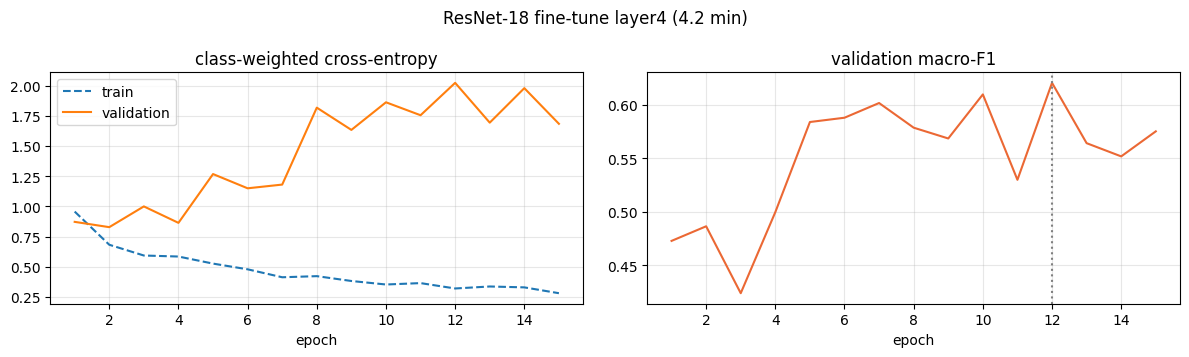

ResNet-18 fine-tune layer4: validation macro-F1 = 0.621


In [7]:
res4, res4_hist = finetune("ResNet-18 fine-tune layer4")

## 5. Mini challenge: unfreeze layer3 + layer4 + fc
Same recipe, more trainable weights. Is it worth the extra cost?

ResNet-18 fine-tune layer3+4: 10,494,979 trainable of 11,178,051 parameters
  epoch  1: train loss 0.953 | val loss 0.852 | val macro-F1 0.541 | 17s
  epoch  2: train loss 0.660 | val loss 0.770 | val macro-F1 0.543 | 17s
  epoch  3: train loss 0.576 | val loss 0.788 | val macro-F1 0.495 | 17s
  epoch  4: train loss 0.518 | val loss 0.860 | val macro-F1 0.591 | 16s
  epoch  5: train loss 0.498 | val loss 1.472 | val macro-F1 0.609 | 16s
  epoch  6: train loss 0.434 | val loss 1.145 | val macro-F1 0.592 | 17s
  epoch  7: train loss 0.418 | val loss 1.382 | val macro-F1 0.601 | 18s
  epoch  8: train loss 0.366 | val loss 1.205 | val macro-F1 0.615 | 17s
  epoch  9: train loss 0.327 | val loss 1.412 | val macro-F1 0.612 | 16s
  epoch 10: train loss 0.313 | val loss 1.299 | val macro-F1 0.554 | 17s
  epoch 11: train loss 0.291 | val loss 1.362 | val macro-F1 0.569 | 16s
  epoch 12: train loss 0.253 | val loss 1.692 | val macro-F1 0.631 | 17s
  epoch 13: train loss 0.274 | val loss 1.565 | 

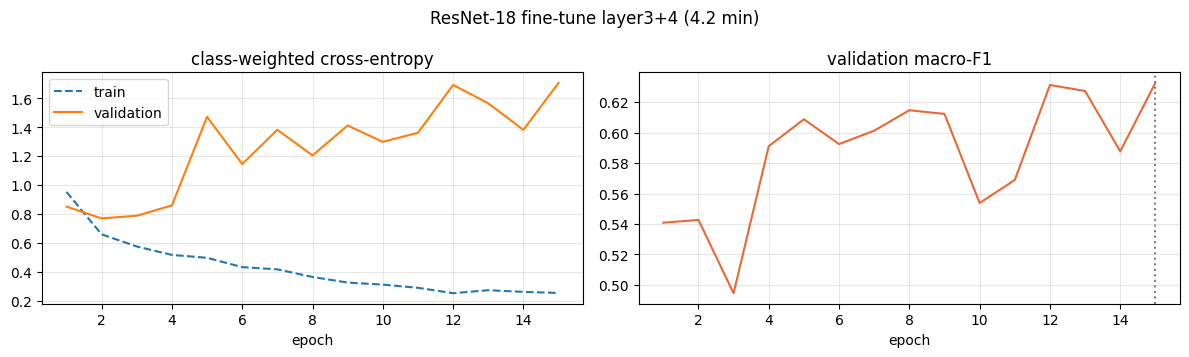

ResNet-18 fine-tune layer3+4: validation macro-F1 = 0.633


In [8]:
res34, res34_hist = finetune("ResNet-18 fine-tune layer3+4")

## 6. Milestone 3 summary (validation only)

In [9]:
registry = json.loads(REGISTRY.read_text())
m3_names = ["CNN from scratch", "ResNet-18 frozen + head", "ResNet-18 fine-tune layer4", "ResNet-18 fine-tune layer3+4"]
m3 = pd.DataFrame([{"model": n, "val macro-F1": registry[n]["val_macro_f1"],
                    "trainable params": registry[n]["trainable params"],
                    "best epoch": registry[n].get("best epoch"), "sec / epoch": registry[n].get("sec per epoch"),
                    "minutes": registry[n].get("minutes")} for n in m3_names if n in registry])
m3.to_csv(DEEP / "m3_summary.csv", index=False)
m3

,model,val macro-F1,trainable params,best epoch,sec / epoch,minutes
0,CNN from scratch,0.5245,390147,11,18.3,5.8
1,ResNet-18 frozen + head,0.6034,1539,9,NaN,NaN
2,ResNet-18 fine-tune layer4,0.6207,8395267,12,16.7,4.2
3,ResNet-18 fine-tune layer3+4,0.6326,10494979,15,16.9,4.2


**Observations M3** (validation macro-F1, 3 classes; for comparison: SVM on 45 features 0.567, MLP on
45 features 0.559, MLP on raw pixels 0.540)

- **CNN from scratch: 0.525.** That is *below* every handcrafted-feature model. With only 3,143 training lesions,
  learning all 390,147 weights from zero is not enough: the network has to discover edges, colours and textures
  on its own (Session 7: "a CNN needs lots of images").
- **Pretrained ResNet-18, frozen + head: 0.603** with only 1,539 trained weights. Features learned on ImageNet,
  which has never seen a skin lesion, already beat 45 features designed by hand for this task. This is transfer
  learning.
- **Fine-tuning helps a little more:** layer4 + fc reached 0.621 and layer3 + layer4 + fc reached **0.633**, at the
  same cost per epoch (about 17 s on a T4). Adapting the higher layers to dermoscopy pays off.
  - **Mini challenge answer:** unfreezing layer3 too (+2.1 M weights) gave +0.012 on validation. That is less than
    the epoch-to-epoch noise of the validation curve (±0.05), so it is a small gain at best.
- **Overconfidence:** in every fine-tuned model the validation **loss rises** (0.77 → 1.7) while the validation
  **macro-F1 still improves**. The model gets more decisions right but becomes extremely sure of the wrong ones,
  which the loss punishes heavily. Early stopping on validation macro-F1 keeps the best epoch.
- **Limitation:** one training run per fine-tuned model (one seed). Differences of about 0.01–0.02 between them
  are within the noise.